# 配送延迟与评分预测

用订单特征预测该订单是否会得到差评（≤2 星），检验「物流延迟」信号的预测力。

差评率 12.8%
随机森林 AUC = 0.673 | 仅用"迟到天数" AUC = 0.649


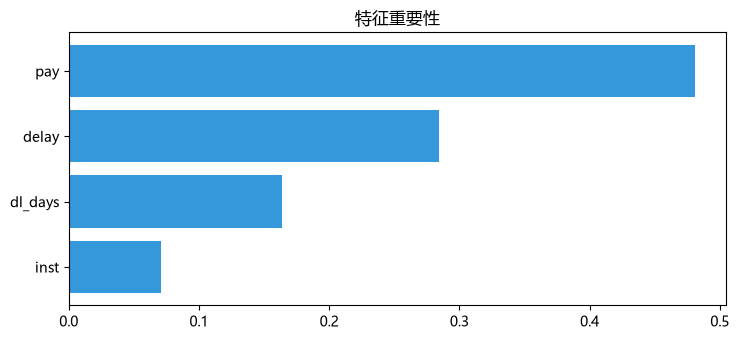

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

orders = pd.read_csv('data/orders_clean.csv', parse_dates=[
    'order_purchase_timestamp', 'order_estimated_delivery_date', 'order_delivered_customer_date'])
payments = pd.read_csv('data/order_payments_clean.csv')
reviews = pd.read_csv('data/order_reviews_clean.csv').drop_duplicates('order_id')

o = orders[orders['order_status'] == 'delivered'].drop_duplicates('order_id')
po = payments.groupby('order_id').agg(pay=('payment_value', 'sum'),
                                      inst=('payment_installments', 'max'))
o['pay'] = o['order_id'].map(po['pay']); o['inst'] = o['order_id'].map(po['inst'])
o['score'] = o['order_id'].map(reviews.set_index('order_id')['review_score'])
o['dl_days'] = (o['order_delivered_customer_date'] - o['order_purchase_timestamp']).dt.days
o['delay'] = (o['order_delivered_customer_date'] - o['order_estimated_delivery_date']).dt.days
o = o.dropna(subset=['pay', 'inst', 'score', 'dl_days', 'delay'])

X = o[['delay', 'dl_days', 'pay', 'inst']]
y = (o['score'] <= 2).astype(int)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=42, stratify=y)
m = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(Xtr, ytr)
auc_rf = roc_auc_score(yte, m.predict_proba(Xte)[:, 1])
auc_delay = roc_auc_score(yte, Xte['delay'])
print('差评率 %.1f%%' % (y.mean() * 100))
print('随机森林 AUC = %.3f | 仅用"迟到天数" AUC = %.3f' % (auc_rf, auc_delay))

imp = pd.Series(m.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.barh(imp.index, imp.values, color='#3498db')
ax.set_title('特征重要性')
plt.tight_layout(); plt.show()


## 结论

- **迟到天数是最强预测因子**：随机森林 AUC 0.673；只用"迟到天数"单一特征就有 AUC 0.649——其他特征几乎不增加信息量。
- 特征重要性上，迟到天数与总配送时长合计约 0.45；金额、分期等交易特征贡献有限。
- **落地建议**：差评可被"预计延误"提前预知——当系统预测订单将迟到时，主动推送延误通知 + 小额补偿券，即可拦截大部分潜在差评（迟到订单差评率 61%，准时订单仅 9%）。

## 业务解读

- 模型的价值不在精度（AUC 0.673 是中等水平）而在**预警时机**：订单发运后一旦预测差评概率高，即可触发「主动通知 + 补偿券」干预，把差评拦截在发生之前。
- 单一特征「迟到天数」AUC 0.649 说明评分信号 50% 以上来自物流——这与差评归因分析（迟到差评率 61%）互相印证，形成「归因→预测→干预」的完整证据链。
- 干预 ROI 测算：迟到订单占 6.8%（约 6,500 单），差评率 61%→假设通知+券可砍半至 30%，可减少约 2,000 个差评，差评率从 12.9% 降至约 11%——对搜索排名与卖家生态是显著改善。
- 局限：模型特征全是事后变量（实际送达后才知迟到），要用于**事前**干预需换用发运时点可得的特征（预计延误、卖家历史准时率、目的地州），是明确的迭代方向。

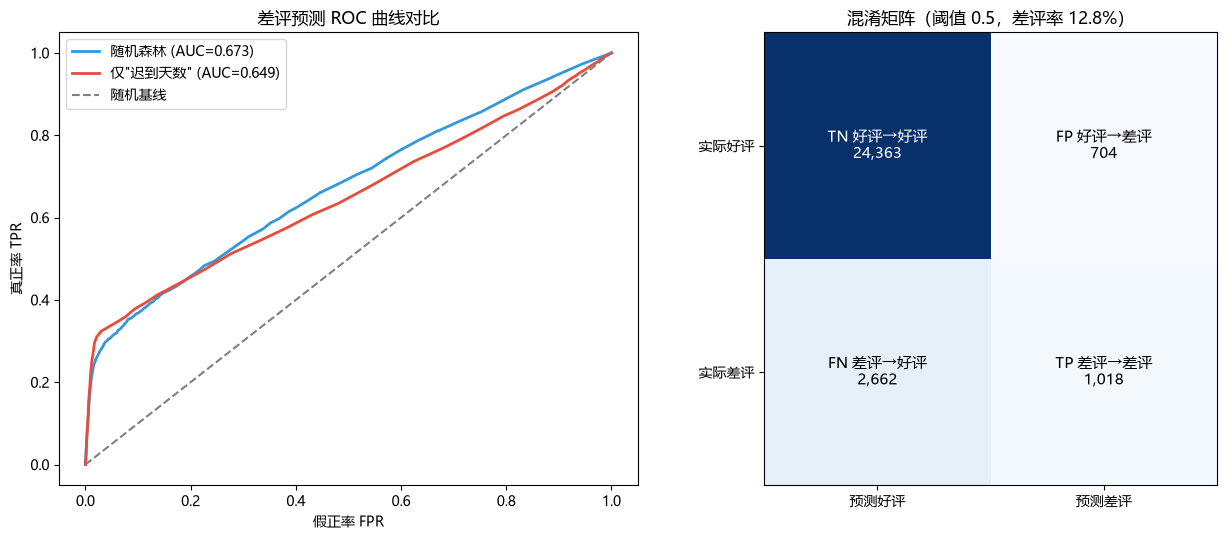

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

from sklearn.metrics import roc_curve, confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# ① ROC 对比：随机森林 vs 仅 delay 特征 vs 随机基线
prob = m.predict_proba(Xte)[:, 1]
fpr1, tpr1, _ = roc_curve(yte, prob)
fpr2, tpr2, _ = roc_curve(yte, Xte['delay'])
axes[0].plot(fpr1, tpr1, color='#3498db', lw=2, label=f'随机森林 (AUC={auc_rf:.3f})')
axes[0].plot(fpr2, tpr2, color='#e74c3c', lw=2, label=f'仅"迟到天数" (AUC={auc_delay:.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', ls='--', label='随机基线')
axes[0].set_xlabel('假正率 FPR'); axes[0].set_ylabel('真正率 TPR')
axes[0].set_title('差评预测 ROC 曲线对比')
axes[0].legend()

# ② 混淆矩阵（阈值 0.5）
pred = (prob >= 0.5).astype(int)
cm = confusion_matrix(yte.astype(int), pred, labels=[0, 1])
lbl = [['TN 好评→好评', 'FP 好评→差评'], ['FN 差评→好评', 'TP 差评→差评']]
im = axes[1].imshow(cm, cmap='Blues')
axes[1].set_xticks([0, 1], ['预测好评', '预测差评'])
axes[1].set_yticks([0, 1], ['实际好评', '实际差评'])
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f'{lbl[i][j]}\n{cm[i, j]:,}', ha='center', va='center',
                     fontsize=11, color='white' if cm[i, j] > cm.max() / 2 else 'black')
axes[1].set_title(f'混淆矩阵（阈值 0.5，差评率 {yte.mean():.1%}）')

plt.tight_layout()
plt.show()